[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S08/2_Practica/para_casa/S08_03_boosting_xgboost_lightgbm.ipynb)

# S08 · 03 — Boosting: Gradient Boosting, XGBoost y LightGBM

Sprint 8 · M3 (UD 3.7)

**Contexto TurisData.** El bosque promedia árboles independientes. El **boosting** hace algo distinto: entrena árboles **pequeños y en cadena**, cada uno dedicado a **corregir los errores del anterior**. Es la familia que suele ganar en datos tabulares como los de TurisData. Probamos la versión de scikit-learn y las dos librerías estrella: **XGBoost** y **LightGBM**.

**Este cuaderno tiene 3 ejercicios y un mini-reto.** Los ejercicios 1 y 2 son los mismos que los del cuaderno «en clase» (allí, del 1 al 2).

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [1]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")
SEMILLA = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["temporada_alta"] = df["fecha_llegada"].dt.month.isin([1, 2, 3, 7, 8, 12]).astype(int)
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), columnas_cat),
])
Xtr = prep.fit_transform(X_train)
Xte = prep.transform(X_test)
nombres = prep.get_feature_names_out()

# Para la parada temprana necesitamos un conjunto de VALIDACIÓN aparte (sacado de train, no del test)
Xfit, Xval, yfit, yval = train_test_split(Xtr, y_train, test_size=0.2, random_state=SEMILLA, stratify=y_train)
print("Entrenar:", len(Xfit), "· validar:", len(Xval), "· probar (test, intacto):", len(Xte))
print("Listo ✔")

Entrenar: 3840 · validar: 960 · probar (test, intacto): 1200
Listo ✔


### 👀 A2 · EJEMPLO — El AUC según el número de árboles (¿se sobreajusta?)

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A2).

1. ¿Con cuántos árboles es máximo el AUC de validación y cuánto vale?
2. ¿Qué pasa con el AUC de entrenamiento al seguir añadiendo árboles?
3. ¿Qué indica que validación baje mientras entrenamiento sube?

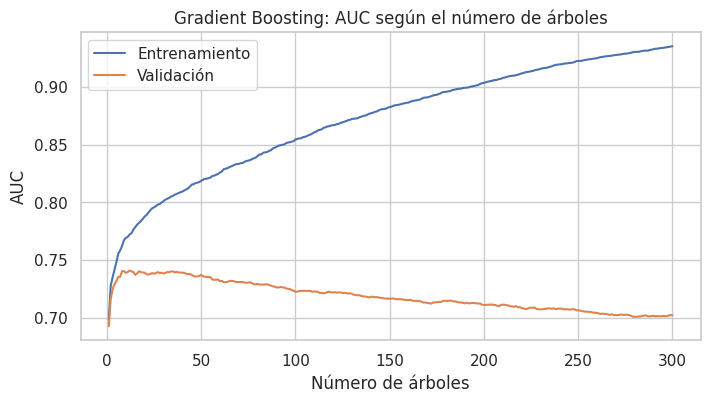

In [2]:
gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.2, max_depth=3, random_state=SEMILLA).fit(Xfit, yfit)
auc_val_por_arbol = [roc_auc_score(yval, p[:, 1]) for p in gb.staged_predict_proba(Xval)]
auc_fit_por_arbol = [roc_auc_score(yfit, p[:, 1]) for p in gb.staged_predict_proba(Xfit)]
plt.figure(figsize=(8, 4))
plt.plot(range(1, 301), auc_fit_por_arbol, label="Entrenamiento")
plt.plot(range(1, 301), auc_val_por_arbol, label="Validación")
plt.title("Gradient Boosting: AUC según el número de árboles")
plt.xlabel("Número de árboles")
plt.ylabel("AUC")
plt.legend()
plt.show()

### ✏️ A3 · EJERCICIO 1 de 3 — El mejor número de árboles y cuánto cae el AUC

**Tu turno:** Con la lista `auc_val_por_arbol`, guarda en `mejor_n_arboles` el número de árboles (empezando a contar en 1) con mejor AUC de validación, y en `caida_final` cuánto ha caído el AUC de validación con los 300 árboles respecto a ese máximo (valor positivo).

**Debe salir:** `Mejor nº de árboles: 12 · pérdida de AUC si seguimos hasta 300: 0.039` y ✔ Ejercicio 1 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A3).

1. ¿Qué valen `mejor_n_arboles` y `caida_final`?
2. ¿Por qué hay que sumar 1 a `np.argmax(...)`?
3. ¿Qué pierdes por seguir hasta 300 árboles?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A3, **después de intentarlo**.

In [3]:
# pista: np.argmax(...) + 1 para el nº de árboles; max(...) - último valor para la caída
mejor_n_arboles = int(np.argmax(auc_val_por_arbol)) + 1
caida_final = max(auc_val_por_arbol) - auc_val_por_arbol[-1]

assert 1 <= mejor_n_arboles < 100, "Con learning_rate 0,2 el óptimo llega pronto (pocas decenas de árboles)"
assert caida_final > 0.02, "Con 300 árboles el AUC de validación debería haber caído: sobreajuste"
print(f"Mejor nº de árboles: {mejor_n_arboles} · pérdida de AUC si seguimos hasta 300: {caida_final:.3f}")
print("✔ Ejercicio 1 correcto")

Mejor nº de árboles: 12 · pérdida de AUC si seguimos hasta 300: 0.039
✔ Ejercicio 1 correcto


### ✏️ A4 · EJERCICIO 2 de 3 — XGBoost con parada temprana

**Tu turno:** Entrena `modelo_xgb = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=30, eval_metric="auc", random_state=SEMILLA, n_jobs=2)` con `Xfit, yfit` y `eval_set=[(Xval, yval)]` (usa `verbose=False`). Guarda `arboles_xgb` (`modelo_xgb.best_iteration`) y `auc_test_xgb` (AUC en test).

**Debe salir:** `XGBoost paró en 69 árboles · AUC test = 0.745` y ✔ Ejercicio 2 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A4).

1. ¿En cuántos árboles paró XGBoost y qué AUC da en test?
2. ¿Por qué se usa un `eval_set` separado y no el test?
3. Comparado con el Gradient Boosting del ejemplo (óptimo en 12 árboles, AUC val 0,741), ¿qué cambia?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A4, **después de intentarlo**.

In [4]:
# pista: crea modelo_xgb y haz modelo_xgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], verbose=False)
modelo_xgb = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8,
                               colsample_bytree=0.8, early_stopping_rounds=30, eval_metric="auc",
                               random_state=SEMILLA, n_jobs=2)
modelo_xgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], verbose=False)
arboles_xgb = int(modelo_xgb.best_iteration)
auc_test_xgb = roc_auc_score(y_test, modelo_xgb.predict_proba(Xte)[:, 1])

assert 5 < arboles_xgb < 1000, "La parada temprana debería detener el entrenamiento antes del máximo"
assert auc_test_xgb > 0.72, "El AUC de XGBoost en test debería superar 0,72"
print(f"XGBoost paró en {arboles_xgb} árboles · AUC test = {auc_test_xgb:.3f}")
print("✔ Ejercicio 2 correcto")

XGBoost paró en 69 árboles · AUC test = 0.745
✔ Ejercicio 2 correcto


### ✏️ A5 · EJERCICIO 3 de 3 — LightGBM con parada temprana

**Tu turno:** Entrena `modelo_lgb = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=8, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA, n_jobs=2, verbose=-1)` con `Xfit, yfit`, `eval_set=[(Xval, yval)]`, `eval_metric="auc"` y `callbacks=[lgb.early_stopping(30, verbose=False)]`. Guarda `arboles_lgb` (`modelo_lgb.best_iteration_`) y `auc_test_lgb`.

**Debe salir:** `LightGBM paró en 49 árboles · AUC test = 0.745` y ✔ Ejercicio 3 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A5).

1. ¿En cuántos árboles paró LightGBM y qué AUC da en test?
2. ¿Qué controla `num_leaves=8` en lugar de `max_depth`?
3. Comparado con XGBoost (69 árboles, 0.745), ¿qué conclusión sacas?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A5, **después de intentarlo**.

In [5]:
# pista: modelo_lgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], eval_metric="auc", callbacks=[lgb.early_stopping(30, verbose=False)])
modelo_lgb = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=8, subsample=0.8,
                                subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA, n_jobs=2, verbose=-1)
modelo_lgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], eval_metric="auc",
               callbacks=[lgb.early_stopping(30, verbose=False)])
arboles_lgb = int(modelo_lgb.best_iteration_)
auc_test_lgb = roc_auc_score(y_test, modelo_lgb.predict_proba(Xte)[:, 1])

assert 5 < arboles_lgb < 1000, "La parada temprana debería detener el entrenamiento antes del máximo"
assert auc_test_lgb > 0.72, "El AUC de LightGBM en test debería superar 0,72"
print(f"LightGBM paró en {arboles_lgb} árboles · AUC test = {auc_test_lgb:.3f}")
print("✔ Ejercicio 3 correcto")

LightGBM paró en 49 árboles · AUC test = 0.745
✔ Ejercicio 3 correcto


### 👀 A6 · EJEMPLO — Importancia de variables de XGBoost

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A6).

1. ¿Qué variable aparece la primera y cuántas barras se muestran?
2. ¿Qué grupos de variables dominan?
3. ¿Por qué «describen el modelo, no la causalidad»?

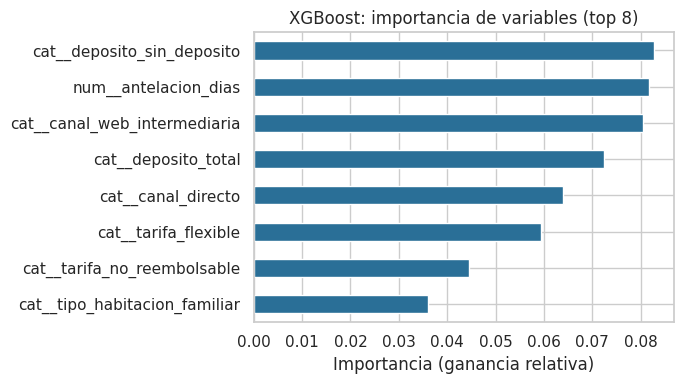

In [6]:
imp = pd.Series(modelo_xgb.feature_importances_, index=nombres).sort_values(ascending=False).head(8)
plt.figure(figsize=(7, 4))
imp.iloc[::-1].plot(kind="barh", color="#2a6f97")
plt.title("XGBoost: importancia de variables (top 8)")
plt.xlabel("Importancia (ganancia relativa)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### ✏️ A7 · MINI-RETO — Comparar sklearn, XGBoost y LightGBM

**Tu turno:** Crea `tabla`, un DataFrame con filas `"sklearn_gb"`, `"xgboost"` y `"lightgbm"` y columnas `auc_test`, `arboles` y `segundos_ajuste` (tiempo de `fit` medido con `time.perf_counter()`). Para `sklearn_gb` usa `GradientBoostingClassifier(learning_rate=0.05, max_depth=3, subsample=0.8, n_estimators=1000, n_iter_no_change=30, validation_fraction=0.2, random_state=SEMILLA)` sobre **todo** `Xtr` (esta versión también sabe parar antes: `n_estimators_` dice cuántos árboles usó). Para XGBoost y LightGBM reentrénalos con los mismos parámetros de los ejercicios (con `Xfit`/`Xval`) midiendo el tiempo.

**Debe salir:** ✔ Mini-reto correcto y la tabla `tabla` (AUC ≈ 0,744 · 0,745 · 0,745; árboles 139 · 69 · 49)

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A7).

1. ¿Qué AUC y cuántos árboles tiene cada implementación?
2. ¿Qué implementación es la más rápida y cuál la más lenta?
3. ¿Qué elegirías con estos resultados?

In [7]:
# pista: mide t0 = time.perf_counter() antes de cada .fit y resta después; n_estimators_ en sklearn
filas = {}
t0 = time.perf_counter()
gb2 = GradientBoostingClassifier(learning_rate=0.05, max_depth=3, subsample=0.8, n_estimators=1000,
                                 n_iter_no_change=30, validation_fraction=0.2, random_state=SEMILLA).fit(Xtr, y_train)
filas["sklearn_gb"] = {"auc_test": roc_auc_score(y_test, gb2.predict_proba(Xte)[:, 1]),
                       "arboles": int(gb2.n_estimators_), "segundos_ajuste": time.perf_counter() - t0}
t0 = time.perf_counter()
x2 = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                       early_stopping_rounds=30, eval_metric="auc", random_state=SEMILLA, n_jobs=2)
x2.fit(Xfit, yfit, eval_set=[(Xval, yval)], verbose=False)
filas["xgboost"] = {"auc_test": roc_auc_score(y_test, x2.predict_proba(Xte)[:, 1]),
                    "arboles": int(x2.best_iteration), "segundos_ajuste": time.perf_counter() - t0}
t0 = time.perf_counter()
l2 = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=8, subsample=0.8, subsample_freq=1,
                        colsample_bytree=0.8, random_state=SEMILLA, n_jobs=2, verbose=-1)
l2.fit(Xfit, yfit, eval_set=[(Xval, yval)], eval_metric="auc", callbacks=[lgb.early_stopping(30, verbose=False)])
filas["lightgbm"] = {"auc_test": roc_auc_score(y_test, l2.predict_proba(Xte)[:, 1]),
                     "arboles": int(l2.best_iteration_), "segundos_ajuste": time.perf_counter() - t0}
tabla = pd.DataFrame(filas).T
tabla["arboles"] = tabla["arboles"].astype(int)
tabla = tabla.round(3)
tabla

assert list(tabla.index) == ["sklearn_gb", "xgboost", "lightgbm"], "Filas en el orden pedido"
assert {"auc_test", "arboles", "segundos_ajuste"} <= set(tabla.columns)
assert tabla["auc_test"].between(0.70, 0.80).all(), "Los tres deberían tener AUC entre 0,70 y 0,80"
display(tabla)
print("✔ Mini-reto correcto")

,auc_test,arboles,segundos_ajuste
sklearn_gb,0.744,139,2.035
xgboost,0.745,69,0.337
lightgbm,0.745,49,0.177


✔ Mini-reto correcto


# Parte B · Explicación de cada celda y de cada resultado

Cada apartado lleva el **mismo número** que su celda de la Parte A (A1, A2…). Si una celda no te sale, mira su «Si falla».

#### A1 · Preparación — Preparar las herramientas y los datos

- **Qué hace:**
    - Carga las herramientas: `pandas`, `numpy`, `matplotlib`, `seaborn`, el `GradientBoostingClassifier` de scikit-learn, `XGBoost` y `LightGBM`, y el preprocesado.
    - `dato(...)` busca un archivo de datos del curso y, si no está, lo descarga del repositorio.
    - Lee `reservas_turisdata.csv` (6000 reservas), crea `temporada_alta` y define `X` (9 numéricas y 6 categóricas) e `y` (si la reserva se cancela). Reparte train y test (80 % / 20 %).
    - Define `prep` y produce `Xtr`, `Xte` y `nombres`.
    - Para la **parada temprana** separa de train un conjunto de **validación** (`Xfit`/`yfit` para entrenar y `Xval`/`yval` para validar): el test queda intacto.
- **Qué debe salir:**
    - `Entrenar: 3840 · validar: 960 · probar (test, intacto): 1200` y `Listo ✔`.
- **Cómo leerlo:**
    - No hay que entender esta celda: solo ejecutarla **la primera**, y otra vez si reinicias el entorno.
- **Si falla:**
    - `NameError: name 'pd' is not defined` → no has ejecutado esta celda. Ejecútala y repite la que falló.

## 1. La idea del boosting y su sobreajuste

#### A2 · Ejemplo — El AUC según el número de árboles (¿se sobreajusta?)

1. El primer árbol (muy pequeño) hace una predicción básica.
2. Se miran los **errores** que comete (los «residuos»).
3. El segundo árbol se entrena para **predecir esos errores** y se suma al primero, multiplicado por un paso pequeño: el **`learning_rate`** (tasa de aprendizaje).
4. Se repite cientos de veces.

| | Bosque (*bagging*) | Boosting |
|---|---|---|
| Árboles | Grandes, independientes, en paralelo | Pequeños, en cadena, cada uno corrige al anterior |
| Reduce sobre todo | Varianza | Sesgo (y, con cuidado, también varianza) |
| Riesgo | Poco sobreajuste | **Sobreajusta si se añaden demasiados árboles** |
| Ajuste | Poco sensible | Sensible: `learning_rate`, nº de árboles, profundidad |

Con `GradientBoostingClassifier` podemos ver cómo evoluciona el AUC **de validación** a medida que se añaden árboles (`staged_predict_proba`). Usamos una tasa de aprendizaje alta (0,2) para ver el efecto con claridad.

- **Qué hace:**
    - `GradientBoostingClassifier(n_estimators=300, learning_rate=0.2, max_depth=3, ...)` entrena 300 árboles pequeños en cadena con `Xfit`/`yfit`.
    - `gb.staged_predict_proba(...)` da las predicciones del modelo **tras cada árbol añadido**; `auc_val_por_arbol` y `auc_fit_por_arbol` son el AUC tras cada árbol, en validación y en entrenamiento.
    - Dibuja las dos curvas.
- **Qué debe salir:**
    - Un gráfico con dos curvas: la de **entrenamiento** sube sin parar hasta ≈ 0,94; la de **validación** sube hasta ≈ 0,741 (con 12 árboles) y luego **baja** hasta ≈ 0,702 con 300.
- **Cómo leerlo:**
    - La separación entre las dos curvas es el **sobreajuste**: el modelo sigue mejorando en lo que ya vio y empeora en lo que no vio.
- **Si falla:**
    - `NameError: name 'Xfit' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Con cuántos árboles es máximo el AUC de validación y cuánto vale?* → Con **12 árboles**: AUC de validación **≈ 0,741**.
2. *¿Qué pasa con el AUC de entrenamiento al seguir añadiendo árboles?* → **Sigue subiendo** hasta ≈ 0,935: el modelo memoriza el entrenamiento.
3. *¿Qué indica que validación baje mientras entrenamiento sube?* → **Sobreajuste**: el boosting sobreajusta si se añaden demasiados árboles. Por eso hay que parar en el mejor punto.

</details>

#### A3 · Ejercicio 1 — El mejor número de árboles y cuánto cae el AUC

- **Qué hace:**
    - `np.argmax(auc_val_por_arbol)` da la **posición** del mayor AUC de validación; como se cuenta desde 0, se suma 1 para obtener el número de árboles (`mejor_n_arboles`).
    - `max(auc_val_por_arbol) - auc_val_por_arbol[-1]` es el AUC máximo menos el de los 300 árboles (el último): lo que se ha perdido (`caida_final`).
- **Qué debe salir:**
    - `Mejor nº de árboles: 12 · pérdida de AUC si seguimos hasta 300: 0.039`.
    - `✔ Ejercicio 1 correcto`.
- **Si falla:**
    - `Con learning_rate 0,2 el óptimo llega pronto (pocas decenas de árboles)` → te has olvidado del `+ 1`, o has cogido `max(...)`, que es el AUC y no la posición.
    - `Con 300 árboles el AUC de validación debería haber caído: sobreajuste` → has restado al revés (último menos máximo, que da negativo) o has usado la curva de entrenamiento.
    - `NameError: name 'auc_val_por_arbol' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué valen `mejor_n_arboles` y `caida_final`?* → **12** y **≈ 0,039**.
2. *¿Por qué hay que sumar 1 a `np.argmax(...)`?* → Porque `argmax` da una **posición** (empieza en 0) y el nº de árboles empieza en 1: la posición 11 es el árbol nº 12.
3. *¿Qué pierdes por seguir hasta 300 árboles?* → **0,039 de AUC** en validación (de 0,741 a 0,702) y además tiempo de cálculo: un modelo peor y más caro.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
mejor_n_arboles = int(np.argmax(auc_val_por_arbol)) + 1
caida_final = max(auc_val_por_arbol) - auc_val_por_arbol[-1]
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 2. XGBoost

#### A4 · Ejercicio 2 — XGBoost con parada temprana

**Solución práctica: parada temprana.** En lugar de adivinar cuántos árboles, se pone un máximo alto y se **detiene el entrenamiento cuando la validación deja de mejorar** durante N rondas seguidas. Además, una tasa de aprendizaje **más baja** (0,03–0,1) y más árboles suele dar mejores modelos.

XGBoost es una implementación muy optimizada del boosting con **regularización** incorporada. Hiperparámetros principales:

| Hiperparámetro | Qué controla |
|---|---|
| `n_estimators` | Máximo de árboles (con parada temprana, se pone alto) |
| `learning_rate` | Paso de cada árbol (menor = más lento pero más fino) |
| `max_depth` | Profundidad de cada árbol (2–6 suele bastar) |
| `subsample` / `colsample_bytree` | Fracción de filas / columnas por árbol (reducen la varianza) |
| `reg_lambda`, `min_child_weight` | Regularización L2 y tamaño mínimo de nodo |
| `early_stopping_rounds` | Rondas sin mejorar para detenerse |

- **Qué hace:**
    - `xgb.XGBClassifier(...)` crea el modelo: hasta 1000 árboles de profundidad 3, paso `learning_rate=0.05`, cada uno con el 80 % de filas y de columnas, y parada si el AUC de validación no mejora en 30 rondas.
    - `.fit(Xfit, yfit, eval_set=[(Xval, yval)], verbose=False)` entrena con `Xfit` y vigila la validación `Xval` (sin imprimir cada ronda).
    - `modelo_xgb.best_iteration` es la ronda con mejor validación (`arboles_xgb`); `roc_auc_score(y_test, ...)` mide su AUC en test.
- **Qué debe salir:**
    - `XGBoost paró en 69 árboles · AUC test = 0.745`.
    - `✔ Ejercicio 2 correcto`.
- **Si falla:**
    - `La parada temprana debería detener el entrenamiento antes del máximo` → no has pasado `eval_set` al `fit`, así que no hay validación y entrena los 1000 árboles.
    - `El AUC de XGBoost en test debería superar 0,72` → `auc_test_xgb` no se mide en test con `predict_proba` (¿has usado `Xval`?).
    - `NameError: name 'Xval' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿En cuántos árboles paró XGBoost y qué AUC da en test?* → **69** árboles y **0.745**.
2. *¿Por qué se usa un `eval_set` separado y no el test?* → Porque la validación se «usa» para decidir cuándo parar. El **test debe quedar intacto** para evaluar al final con honestidad.
3. *Comparado con el Gradient Boosting del ejemplo (óptimo en 12 árboles, AUC val 0,741), ¿qué cambia?* → Con `learning_rate` más bajo (0,05 en vez de 0,2) hacen falta **más árboles** (69 frente a 12) pero el resultado es más fino y estable: 0,745 en test.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
modelo_xgb = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8,
                               colsample_bytree=0.8, early_stopping_rounds=30, eval_metric="auc",
                               random_state=SEMILLA, n_jobs=2)
modelo_xgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], verbose=False)
arboles_xgb = int(modelo_xgb.best_iteration)
auc_test_xgb = roc_auc_score(y_test, modelo_xgb.predict_proba(Xte)[:, 1])
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 3. LightGBM

#### A5 · Ejercicio 3 — LightGBM con parada temprana

LightGBM (de Microsoft) es otra implementación muy rápida. Diferencias de estilo: hace crecer los árboles **por hojas** (*leaf-wise*), así que el control principal es **`num_leaves`** en lugar de la profundidad; `min_child_samples` (mínimo de reservas por hoja) evita hojas diminutas. La parada temprana se indica con un *callback*.

- **Qué hace:**
    - `lgb.LGBMClassifier(...)` crea el modelo: hasta 1000 árboles de 8 hojas (`num_leaves=8`), `learning_rate=0.05`, con submuestreo de filas (`subsample=0.8`, `subsample_freq=1`) y de columnas (`colsample_bytree=0.8`).
    - `.fit(..., eval_set=[(Xval, yval)], eval_metric="auc", callbacks=[lgb.early_stopping(30, verbose=False)])` entrena vigilando la validación y se detiene tras 30 rondas sin mejorar.
    - `modelo_lgb.best_iteration_` es la mejor ronda (`arboles_lgb`; fíjate en el guion bajo final) y `roc_auc_score` mide el AUC en test.
- **Qué debe salir:**
    - `LightGBM paró en 49 árboles · AUC test = 0.745`.
    - `✔ Ejercicio 3 correcto`.
- **Si falla:**
    - `La parada temprana debería detener el entrenamiento antes del máximo` → falta el `callbacks=[lgb.early_stopping(...)]` (o el `eval_set`): sin ellos entrena los 1000 árboles.
    - `AttributeError: ... has no attribute 'best_iteration'` → en LightGBM se llama `best_iteration_` (con guion bajo al final).
    - `El AUC de LightGBM en test debería superar 0,72` → `auc_test_lgb` no se mide con `y_test` y `Xte`.
    - `NameError: name 'lgb' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿En cuántos árboles paró LightGBM y qué AUC da en test?* → **49** árboles y **0.745**.
2. *¿Qué controla `num_leaves=8` en lugar de `max_depth`?* → El **tamaño de cada árbol**: LightGBM crece por hojas, así que se limita el número de hojas (8) y no los niveles.
3. *Comparado con XGBoost (69 árboles, 0.745), ¿qué conclusión sacas?* → Que llegan al **mismo AUC** (0,745); cambia el número de árboles porque los árboles son de distinto tipo. La implementación importa poco para el rendimiento.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
modelo_lgb = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=8, subsample=0.8,
                                subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA, n_jobs=2, verbose=-1)
modelo_lgb.fit(Xfit, yfit, eval_set=[(Xval, yval)], eval_metric="auc",
               callbacks=[lgb.early_stopping(30, verbose=False)])
arboles_lgb = int(modelo_lgb.best_iteration_)
auc_test_lgb = roc_auc_score(y_test, modelo_lgb.predict_proba(Xte)[:, 1])
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 4. Qué mira el modelo

#### A6 · Ejemplo — Importancia de variables de XGBoost

XGBoost (por «ganancia») y LightGBM (por defecto, por nº de divisiones; con `importance_type="gain"`, por ganancia) también dan importancias de variable. Como siempre: describen el **modelo**, no la causalidad.

- **Qué hace:**
    - `modelo_xgb.feature_importances_` da una importancia por columna (ya con `Xfit` preprocesado, por lo que son las columnas *one-hot*); `pd.Series(..., index=nombres).sort_values(...).head(8)` se queda con las 8 mayores.
    - Dibuja las 8 en barras horizontales.
- **Qué debe salir:**
    - Un gráfico de 8 barras, con valores muy parecidos entre sí (≈ 0,04–0,08): `deposito_sin_deposito` (0,083), `antelacion_dias` (0,082), `canal_web_intermediaria` (0,080), `deposito_total` (0,072), `canal_directo` (0,064), `tarifa_flexible` (0,059), `tarifa_no_reembolsable` (0,045), `tipo_habitacion_familiar` (0,036).
- **Cómo leerlo:**
    - A diferencia del árbol solo (donde `antelacion_dias` valía ≈ 0,45), aquí la importancia está **repartida** entre varias variables: es normal con cientos de árboles.
- **Si falla:**
    - `NameError: name 'modelo_xgb' is not defined` → falta el ejercicio 2.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué variable aparece la primera y cuántas barras se muestran?* → `deposito_sin_deposito` (≈ 0,083), seguida de cerca de `antelacion_dias` (0,082). Se muestran **8** barras.
2. *¿Qué grupos de variables dominan?* → **Depósito, canal, tarifa y antelación**: casi todas son columnas *one-hot* de esas categóricas.
3. *¿Por qué «describen el modelo, no la causalidad»?* → Porque dicen qué columnas usó el modelo para predecir, no si cambiarlas **provoca** que se cancele o no la reserva.

</details>

## 5. Mini-reto: comparativa de las tres implementaciones

#### A7 · Mini-reto — Comparar sklearn, XGBoost y LightGBM

- **Qué hace:**
    - Para cada implementación: se toma `t0 = time.perf_counter()`, se entrena y se calcula `time.perf_counter() - t0` (los segundos de ajuste). Se guarda el AUC en test y el nº de árboles que usó.
    - `sklearn_gb` usa `n_iter_no_change=30` y `validation_fraction=0.2` para parar antes (`n_estimators_` dice cuántos árboles usó) con **todo** `Xtr`. XGBoost y LightGBM se reentrenan con los mismos parámetros de los ejercicios (con `Xfit`/`Xval`).
    - `pd.DataFrame(filas).T` forma la tabla, `tabla["arboles"].astype(int)` deja el nº de árboles como entero y `.round(3)` redondea.
- **Qué debe salir:**
    - `✔ Mini-reto correcto` y la tabla: `sklearn_gb` AUC 0,744 con 139 árboles · `xgboost` 0,745 con 69 · `lightgbm` 0,745 con 49. Los segundos varían mucho según el ordenador y la ejecución: orientativamente, sklearn ≈ 0,7 s y LightGBM/XGBoost, de 0,05 a 0,25 s (la primera vez, XGBoost puede tardar bastante más por el arranque).
- **Cómo leerlo:**
    - Las tres versiones llegan a un AUC muy parecido: **la implementación importa menos que los datos y la validación**. Las diferencias reales suelen estar en la **velocidad** con muchos datos (LightGBM y XGBoost escalan mucho mejor que la versión de scikit-learn) y en el **manejo nativo** de nulos y categóricas (LightGBM y XGBoost lo admiten; aquí lo hemos evitado con el mismo preprocesado para poder comparar).
- **Si falla:**
    - `Filas en el orden pedido` → falta `.T` o el orden no es `sklearn_gb`, `xgboost`, `lightgbm`.
    - `assert {"auc_test", "arboles", "segundos_ajuste"} <= set(tabla.columns)` → alguna columna tiene otro nombre.
    - `Los tres deberían tener AUC entre 0,70 y 0,80` → has medido el AUC en validación o con las clases en lugar de con las probabilidades.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué AUC y cuántos árboles tiene cada implementación?* → `sklearn_gb`: **0,744** con 139 árboles; `xgboost`: **0,745** con 69; `lightgbm`: **0,745** con 49.
2. *¿Qué implementación es la más rápida y cuál la más lenta?* → La más lenta es **sklearn** (≈ 0,7 s) y las más rápidas **LightGBM y XGBoost** (decenas de milisegundos; los tiempos varían entre ejecuciones y la primera vez XGBoost puede ser más lento).
3. *¿Qué elegirías con estos resultados?* → El AUC es **el mismo** (diferencias de 0,001), así que decide el coste: **LightGBM** o XGBoost por velocidad; con pocos datos, cualquiera sirve.

</details>

## 7. Para reflexionar

1. ¿Por qué el boosting puede sobreajustar por añadir árboles y el bosque prácticamente no?
2. ¿Qué haces si el AUC de validación sube durante 400 árboles y no se detiene? ¿Y si sube 20 y luego baja?
3. Reducir `learning_rate` de 0,2 a 0,05 exige más árboles. ¿Qué compensas y qué pagas?
4. Si los tres tienen AUC 0,745 ± 0,01, ¿en qué te fijarías para elegir uno?

<details><summary>Ver respuestas (después de pensarlo)</summary>

1. Porque en el boosting cada árbol **corrige los errores del anterior** y va ajustándose cada vez más al entrenamiento, ruido incluido (en el ejemplo, el AUC de train sube a 0,935 mientras el de validación baja de 0,741 a 0,702). En el bosque los árboles son independientes y se promedian: añadir más solo estabiliza el promedio.
2. Si sube durante 400 y no se detiene, el máximo aún no se ha alcanzado: subir `n_estimators` (o el `learning_rate`). Si sube 20 y luego baja, la **parada temprana** se queda con el mejor punto (los 20 primeros árboles) y descarta el resto.
3. Compensas el sobreajuste: pasos más pequeños dan modelos más finos y estables. Pagas **más árboles**, es decir, más tiempo de entrenamiento y más memoria (en las pruebas, con 0,2 el óptimo está en 12 árboles y con 0,05 XGBoost necesita 69).
4. En el **coste**: tiempo de ajuste y de predicción, facilidad de mantenimiento y explicabilidad. Una diferencia de 0,001 de AUC está muy por debajo de la desviación (±0,01): no es una razón para elegir.

</details>

## 8. Resumen: qué has aprendido
- Boosting = árboles pequeños en cadena que corrigen errores; **learning_rate** y nº de árboles se equilibran.
- **Parada temprana** con un conjunto de validación (nunca el test) evita el sobreajuste y ahorra tiempo.
- XGBoost y LightGBM comparten ideas y difieren en detalles (`max_depth` vs `num_leaves`).
- Lo que decide la elección suele ser el **coste** (tiempo, mantenimiento, explicabilidad), no unas centésimas de AUC.